In [1]:
import numpy as np
import pandas as pd

# Load the CSV splits Matthew made
train_df = pd.read_csv('../data/tracked/train_mel.csv')
val_df   = pd.read_csv('../data/tracked/val_mel.csv')
test_df  = pd.read_csv('../data/tracked/test_mel.csv')

print(train_df.shape)
print(train_df.head())

(6393, 9)
   track_id    genre  genre_id                                mel_path  \
0         2  Hip-Hop         3  ../data/local/processed_mel/000002.npy   
1         5  Hip-Hop         3  ../data/local/processed_mel/000005.npy   
2        10      Pop         6  ../data/local/processed_mel/000010.npy   
3       140     Folk         2  ../data/local/processed_mel/000140.npy   
4       141     Folk         2  ../data/local/processed_mel/000141.npy   

   artist_id                      artist_name  album_id  \
0          1                             AWOL         1   
1          1                             AWOL         1   
2          6                        Kurt Vile         6   
3         54  Alec K. Redfearn & the Eyesores        61   
4         54  Alec K. Redfearn & the Eyesores        60   

             album_title  loaded_duration_seconds  
0   AWOL - A Way Of Life                29.976599  
1   AWOL - A Way Of Life                30.002721  
2      Constant Hitmaker          

X_train shape: (6393, 128, 128)
y_train shape: (6393,)
X_val shape:   (800, 128, 128)
X_test shape:  (800, 128, 128)


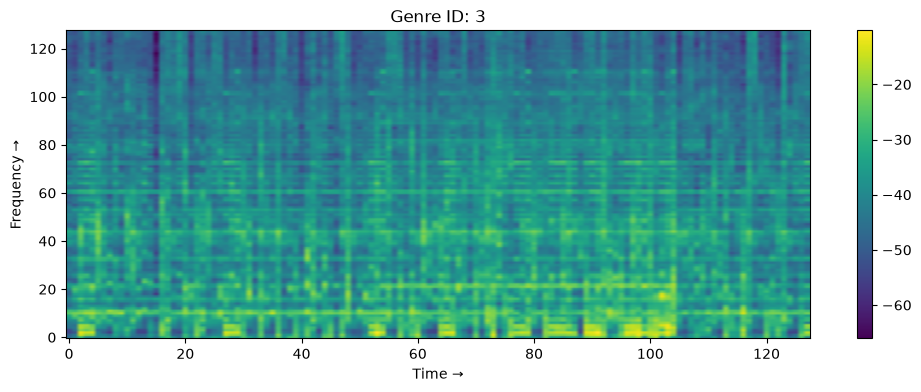

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Load Hussain's compact file
data = np.load('../data/local/mel_compact.npz')

# Use the correct keys (already train/val/test split!)
X_train = data['X_train']
y_train = data['y_train']
X_val   = data['X_val']
y_val   = data['y_val']
X_test  = data['X_test']
y_test  = data['y_test']

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:  ", X_val.shape)
print("X_test shape: ", X_test.shape)

# Show ONE spectrogram
plt.figure(figsize=(12, 4))
plt.imshow(X_train[0], aspect='auto', origin='lower')
plt.title(f"Genre ID: {y_train[0]}")
plt.xlabel("Time →")
plt.ylabel("Frequency →")
plt.colorbar()
plt.show()

In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

# CNN needs a "channel" dimension, like RGB but for audio
# (6393, 128, 128) → (6393, 128, 128, 1)
X_train_m = X_train[..., np.newaxis]
X_val_m   = X_val[...,   np.newaxis]
X_test_m  = X_test[...,  np.newaxis]

print("X_train ready:", X_train_m.shape)  # should be (6393, 128, 128, 1)
print("Num classes:  ", len(np.unique(y_train)))  # should be 8

X_train ready: (6393, 128, 128, 1)
Num classes:   8


In [4]:
model = keras.Sequential([

    # Fix the warning — use Input() as first layer
    keras.Input(shape=(128, 128, 1)),

    # ── CNN PART ──────────────────────────────────────────
    layers.Conv2D(32, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),          # ← NEW: stabilizes training
    layers.MaxPooling2D((2, 4)),          # time: 128→64, freq: 128→32

    layers.Conv2D(64, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),          # ← NEW
    layers.MaxPooling2D((2, 4)),          # time: 64→32, freq: 32→8

    layers.Conv2D(128, (3,3), activation='relu', padding='same'),
    layers.BatchNormalization(),          # ← NEW
    layers.MaxPooling2D((2, 2)),          # time: 32→16, freq: 8→4

    # ── BRIDGE ────────────────────────────────────────────
    layers.Reshape((16, -1)),             # ← 16 steps now (was 128!)

    # ── LSTM PART ─────────────────────────────────────────
    layers.LSTM(64),                      # ← smaller, simpler
    layers.Dropout(0.4),

    # ── OUTPUT ────────────────────────────────────────────
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(8, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 8, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 8, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 8, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 4, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 16, 512)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 245,960 (960.78 KB)

 Trainable params: 245,512 (959.03 KB)

 Non-trainable params: 448 (1.75 KB)

In [5]:
from collections import Counter
import numpy as np

# compute class weights
label_counts = Counter(y_train.tolist())
print("Label counts:", label_counts)

total = len(y_train)
n_classes = 8
class_weight_dict = {
    i: total / (n_classes * label_counts.get(i, 1)) 
    for i in range(n_classes)
}
print("Class weights:", class_weight_dict)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)

history = model.fit(
    X_train_m, y_train,
    validation_data=(X_val_m, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop, reduce_lr],
    class_weight=class_weight_dict    # added class weights to handle imbalance
)

print("\nDone! Best val accuracy:", max(history.history['val_accuracy']))

Label counts: Counter({6: 800, 2: 800, 5: 800, 7: 799, 1: 799, 0: 799, 4: 799, 3: 797})
Class weights: {0: 1.0001564455569463, 1: 1.0001564455569463, 2: 0.99890625, 3: 1.0026662484316187, 4: 1.0001564455569463, 5: 0.99890625, 6: 0.99890625, 7: 1.0001564455569463}
Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 167ms/step - accuracy: 0.2484 - loss: 1.9633 - val_accuracy: 0.1338 - val_loss: 2.2620 - learning_rate: 5.0000e-04
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 16s 164ms/step - accuracy: 0.3377 - loss: 1.8008 - val_accuracy: 0.4050 - val_loss: 1.7220 - learning_rate: 5.0000e-04
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 16s 160ms/step - accuracy: 0.3648 - loss: 1.7486 - val_accuracy: 0.2700 - val_loss: 1.8850 - learning_rate: 5.0000e-04
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 16s 159ms/step - accuracy: 0.3981 - loss: 1.6918 - val_accuracy: 0.3800 - val_loss: 1.7269 - learning_rate: 5.0000e-04
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - accuracy: 0.4092 - loss: 1.6471
Epoch 5: Red

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


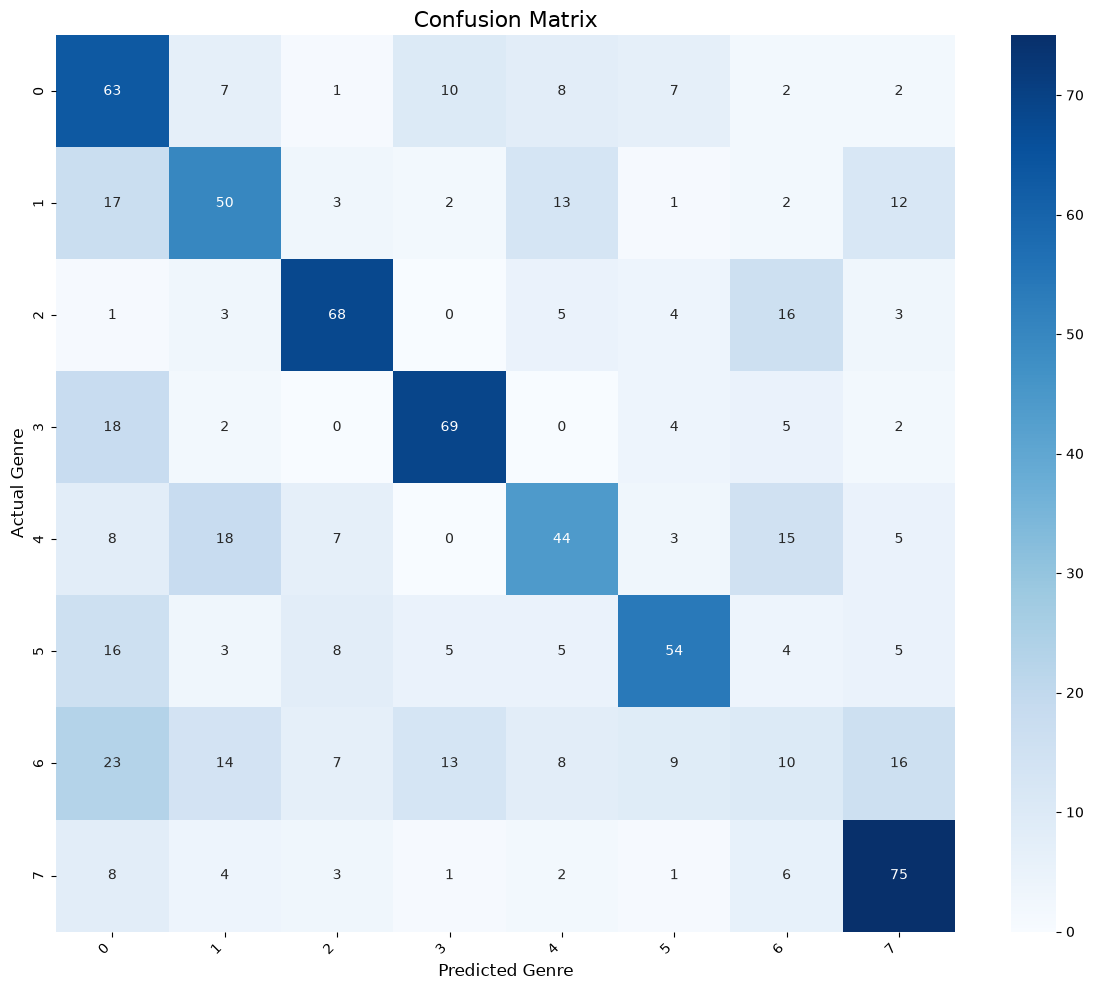


Per-Genre Accuracy Report:
              precision    recall  f1-score   support

           0       0.41      0.63      0.50       100
           1       0.50      0.50      0.50       100
           2       0.70      0.68      0.69       100
           3       0.69      0.69      0.69       100
           4       0.52      0.44      0.48       100
           5       0.65      0.54      0.59       100
           6       0.17      0.10      0.12       100
           7       0.62      0.75      0.68       100

    accuracy                           0.54       800
   macro avg       0.53      0.54      0.53       800
weighted avg       0.53      0.54      0.53       800



In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Get unique genre names directly from your data
genre_names = sorted(np.unique(y_val))

# Get predictions
y_pred_probs = model.predict(X_val_m)
y_pred = np.argmax(y_pred_probs, axis=1)

# ---- Confusion Matrix ----
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=genre_names,
    yticklabels=genre_names
)
plt.title('Confusion Matrix', fontsize=16)
plt.ylabel('Actual Genre', fontsize=12)
plt.xlabel('Predicted Genre', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ---- Per-Genre Breakdown ----
print("\nPer-Genre Accuracy Report:")
# Fix: convert to strings
genre_names = [str(g) for g in sorted(np.unique(y_val))]
print(classification_report(y_val, y_pred, target_names=genre_names))